### Bank Churn Prediction Using ANN

In [54]:
import numpy as np 
import pandas as pd 

In [55]:
df = pd.read_csv('Churn_Modelling.csv')
df.head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


In [56]:
df.CustomerId.duplicated().sum()

np.int64(0)

Data Cleaning

In [57]:
df1 = df.drop(['RowNumber','CustomerId','Surname'] , axis='columns')
df1.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [58]:
df1.dtypes

CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [59]:
df1.Geography.unique()

array(['France', 'Spain', 'Germany'], dtype=object)

Data Visualization 

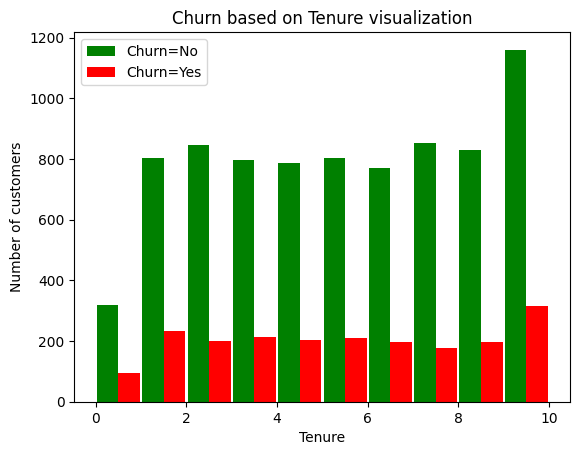

In [60]:
import matplotlib.pyplot as plt 

tenure_churn_no = df1[df1.Exited == 0].Tenure
tenure_churn_yes = df1[df1.Exited == 1].Tenure

plt.xlabel('Tenure')
plt.ylabel('Number of customers')
plt.title('Churn based on Tenure visualization')
plt.hist([tenure_churn_no,tenure_churn_yes], rwidth=0.95 , color=['green', 'red'] , label=['Churn=No','Churn=Yes'])
plt.legend()

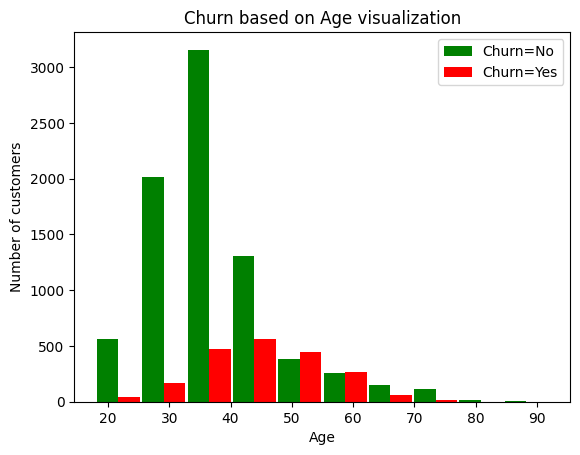

In [61]:
age_churn_no = df1[df1.Exited == 0].Age
age_churn_yes = df1[df1.Exited == 1].Age

plt.xlabel('Age')
plt.ylabel('Number of customers')
plt.title('Churn based on Age visualization')
plt.hist([age_churn_no,age_churn_yes], rwidth=0.95 , color=['green', 'red'] , label=['Churn=No','Churn=Yes'])
plt.legend()

Encoding

In [62]:
df2 = df1.copy()

df2['Gender'] = df2['Gender'].map({'Female' : 1 , 'Male' : 0}) 


In [63]:
df3 = pd.get_dummies(data=df2 , columns=['Geography'] , dtype=int )
df3.sample(10)

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
2610,682,0,38,4,107192.38,1,1,1,15669.17,0,1,0,0
7030,574,0,33,8,100267.03,1,1,0,103006.27,0,1,0,0
4430,588,0,59,4,0.00,2,1,1,27435.41,0,0,0,1
8950,461,1,35,5,0.00,1,1,1,54209.02,0,1,0,0
8265,618,1,40,0,140306.38,1,1,0,160618.61,1,0,1,0
3965,748,1,23,8,85600.08,1,0,0,134077.71,0,0,0,1
2410,596,1,33,1,138162.81,1,1,0,85412.54,0,1,0,0
4903,694,0,42,3,156864.20,2,0,0,88890.75,0,1,0,0
811,681,0,65,7,134714.70,2,0,1,190419.81,0,0,0,1
7024,624,1,45,5,151855.33,1,1,0,68794.15,0,0,1,0


In [66]:
from sklearn.preprocessing import MinMaxScaler 

scaler = MinMaxScaler()

columns_to_scale = ['CreditScore' , 'Balance' , 'EstimatedSalary' , 'Age' , 'Tenure' , 'NumOfProducts']


df3[columns_to_scale] = scaler.fit_transform(df3[columns_to_scale])

In [67]:
df3.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,0.538,1,0.324324,0.2,0.000000,0.000000,1,1,0.506735,1,1,0,0
1,0.516,1,0.310811,0.1,0.334031,0.000000,0,1,0.562709,0,0,0,1
2,0.304,1,0.324324,0.8,0.636357,0.666667,1,0,0.569654,1,1,0,0
3,0.698,1,0.283784,0.1,0.000000,0.333333,0,0,0.469120,0,1,0,0
4,1.000,1,0.337838,0.2,0.500246,0.000000,1,1,0.395400,0,0,0,1


Train , Test Split

In [68]:
from sklearn.model_selection import train_test_split

X = df3.drop('Exited' , axis= 1)
y = df.Exited

X_train , X_test , y_train , y_test = train_test_split(X, y , test_size=0.2 , random_state= 42)

In [70]:
X_train.shape

(8000, 12)

In [71]:
X_test.shape

(2000, 12)

In [69]:
import tensorflow as tf 
from tensorflow import keras

Model Building

In [74]:
model = keras.Sequential([
    keras.Input(shape=(12, )),
    keras.layers.Dense(12,activation='relu'),
    keras.layers.Dense(6, activation='relu'),
    keras.layers.Dense(1,activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=100)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7790 - loss: 0.5398
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7945 - loss: 0.4833
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7945 - loss: 0.4720
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7962 - loss: 0.4640
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8043 - loss: 0.4551
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8108 - loss: 0.4454
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8159 - loss: 0.4353
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8191 - loss: 0.4276
Epoch 9/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8213 - loss: 0.4228
Epoch 10/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8209 - loss: 0.4178
Epoch 11/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8214 - loss: 0.4142
Epoch 12/100
250/250 ━━━━━━━━━━━━━━━━━━━━

Test and Evaluation 

In [75]:
model.evaluate(X_test,y_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8545 - loss: 0.3462 


[0.34622326493263245, 0.8544999957084656]

In [77]:
yp = model.predict(X_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [81]:
yp[:10]

array([[0.04823476],
       [0.02845472],
       [0.19223386],
       [0.13262288],
       [0.0754237 ],
       [0.01072576],
       [0.1443352 ],
       [0.1683229 ],
       [0.26928967],
       [0.46757498]], dtype=float32)

In [78]:
y_predicted = []

for i in yp:
    if i > 0.5:
        y_predicted.append(1)
    else:
        y_predicted.append(0)
        

In [80]:
y_predicted[:10]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [82]:
y_test[:10]

6252    0
4684    0
1731    0
4742    0
4521    0
6340    0
576     0
5202    1
6363    0
439     0
Name: Exited, dtype: int64

In [84]:
from sklearn.metrics import confusion_matrix , classification_report 

print(classification_report(y_test,y_predicted))

              precision    recall  f1-score   support

           0       0.89      0.94      0.91      1607
           1       0.67      0.51      0.58       393

    accuracy                           0.85      2000
   macro avg       0.78      0.72      0.75      2000
weighted avg       0.84      0.85      0.85      2000



In [ ]:
cm = confusion_matrix(y_test,y_predicted)
cm

array([[1509,   98],
       [ 193,  200]])

Text(50.722222222222214, 0.5, 'Truth')

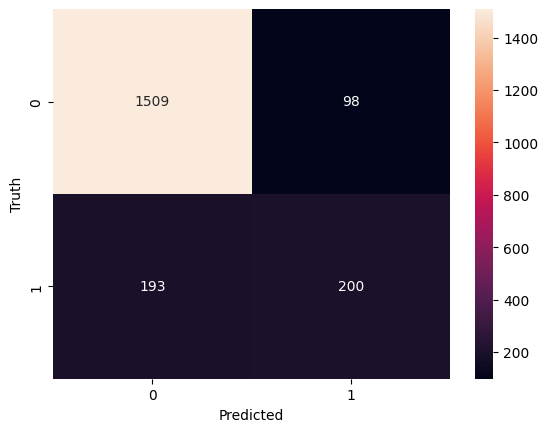

In [92]:
import seaborn as sn 
sn.heatmap(cm,annot=True , fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')